In [204]:
import numpy as np
import pandas as pd

#models ml tools 
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder

from pathlib import Path


from econml.dml import LinearDML, CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


# load dataset

In [205]:
dataset = pd.read_csv(r"E:\internhips\infotact solutions\Dynamic Pricing via Double Machine Learning\backend\data\raw\Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")
dataset

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
63995,10,2) $100 - $200,105.54,1,0,Urban,0,Web,Mens E-Mail,0,0,0.0
63996,5,1) $0 - $100,38.91,0,1,Urban,1,Phone,Mens E-Mail,0,0,0.0
63997,6,1) $0 - $100,29.99,1,0,Urban,1,Phone,Mens E-Mail,0,0,0.0
63998,1,5) $500 - $750,552.94,1,0,Surburban,1,Multichannel,Womens E-Mail,0,0,0.0


In [206]:
dataset.describe

<bound method NDFrame.describe of        recency history_segment  history  mens  womens   zip_code  newbie  \
0           10  2) $100 - $200   142.44     1       0  Surburban       0   
1            6  3) $200 - $350   329.08     1       1      Rural       1   
2            7  2) $100 - $200   180.65     0       1  Surburban       1   
3            9  5) $500 - $750   675.83     1       0      Rural       1   
4            2    1) $0 - $100    45.34     1       0      Urban       0   
...        ...             ...      ...   ...     ...        ...     ...   
63995       10  2) $100 - $200   105.54     1       0      Urban       0   
63996        5    1) $0 - $100    38.91     0       1      Urban       1   
63997        6    1) $0 - $100    29.99     1       0      Urban       1   
63998        1  5) $500 - $750   552.94     1       0  Surburban       1   
63999        1  4) $350 - $500   472.82     0       1  Surburban       0   

            channel        segment  visit  conversion

In [207]:
dataset.columns

Index(['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code',
       'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend'],
      dtype='object')

weightage 

In [208]:
dataset.count()

recency            64000
history_segment    64000
history            64000
mens               64000
womens             64000
zip_code           64000
newbie             64000
channel            64000
segment            64000
visit              64000
conversion         64000
spend              64000
dtype: int64

In [209]:
dataset.isna()
dataset.isna().count()


recency            64000
history_segment    64000
history            64000
mens               64000
womens             64000
zip_code           64000
newbie             64000
channel            64000
segment            64000
visit              64000
conversion         64000
spend              64000
dtype: int64

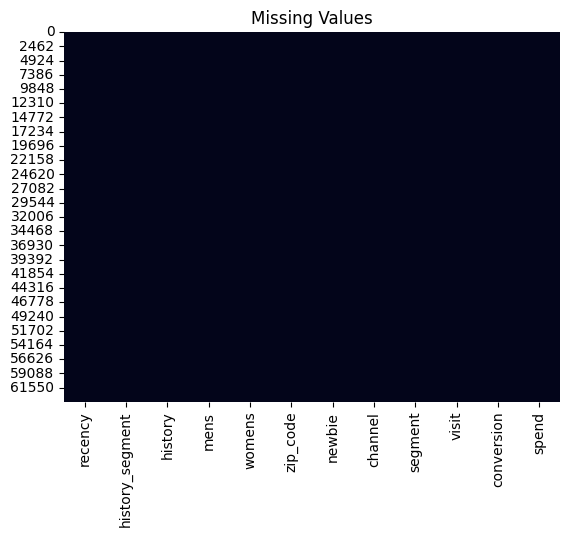

In [210]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(dataset.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

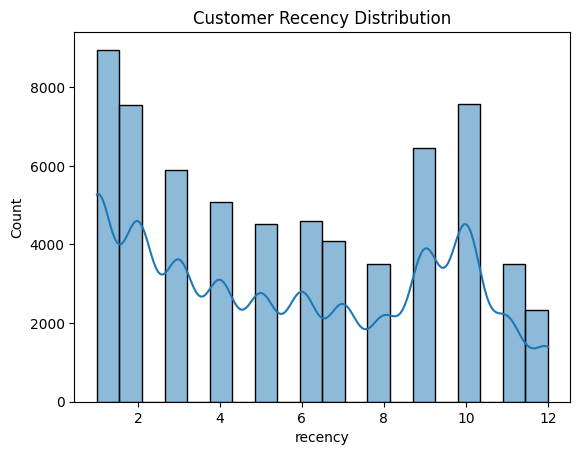

In [211]:
sns.histplot(dataset["recency"], bins=20, kde=True)
plt.title("Customer Recency Distribution")
plt.show()


In [212]:
dataset.head(300)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
295,2,1) $0 - $100,90.91,1,0,Surburban,0,Web,Mens E-Mail,0,0,0.0
296,5,3) $200 - $350,215.03,0,1,Urban,1,Web,No E-Mail,0,0,0.0
297,1,"6) $750 - $1,000",856.40,0,1,Urban,1,Web,No E-Mail,0,0,0.0
298,10,2) $100 - $200,139.83,1,0,Urban,1,Phone,Mens E-Mail,0,0,0.0


In [213]:
le = LabelEncoder()

dataset["zip_code"] = le.fit_transform(dataset["zip_code"])
dataset["channel"] = le.fit_transform(dataset["channel"])

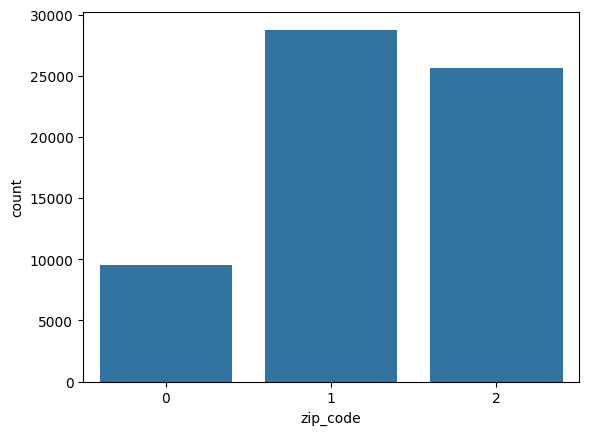

In [214]:
sns.countplot(data=dataset,x="zip_code")
plt.show()

# spliting x,y,t from dataset

In [215]:
X = dataset[
    [
        "recency",
        "history",
        "mens",
        "womens",
        "zip_code",
        "newbie",
        "channel"
    ]
]

Y = dataset["conversion"]

T = dataset["segment"]

In [216]:
print(X)
print("\n")
print(Y)


       recency  history  mens  womens  zip_code  newbie  channel
0           10   142.44     1       0         1       0        1
1            6   329.08     1       1         0       1        2
2            7   180.65     0       1         1       1        2
3            9   675.83     1       0         0       1        2
4            2    45.34     1       0         2       0        2
...        ...      ...   ...     ...       ...     ...      ...
63995       10   105.54     1       0         2       0        2
63996        5    38.91     0       1         2       1        1
63997        6    29.99     1       0         2       1        1
63998        1   552.94     1       0         1       1        0
63999        1   472.82     0       1         1       0        2

[64000 rows x 7 columns]


0        0
1        0
2        0
3        0
4        0
        ..
63995    0
63996    0
63997    0
63998    0
63999    0
Name: conversion, Length: 64000, dtype: int64


In [217]:
print("----------\n")
print(T)

T.unique()

----------

0        Womens E-Mail
1            No E-Mail
2        Womens E-Mail
3          Mens E-Mail
4        Womens E-Mail
             ...      
63995      Mens E-Mail
63996      Mens E-Mail
63997      Mens E-Mail
63998    Womens E-Mail
63999      Mens E-Mail
Name: segment, Length: 64000, dtype: object


array(['Womens E-Mail', 'No E-Mail', 'Mens E-Mail'], dtype=object)

In [218]:
# covert t to numerical
T = T.replace("No E-Mail",0)
T = T.replace("Mens E-Mail",1)
T = T.replace("Womens E-Mail",1)

T.unique()
T.astype(int)

C:\Users\YASHASH RAVI\AppData\Local\Temp\ipykernel_26940\2543953965.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  T = T.replace("Womens E-Mail",1)


0        1
1        0
2        1
3        1
4        1
        ..
63995    1
63996    1
63997    1
63998    1
63999    1
Name: segment, Length: 64000, dtype: int64

In [219]:
Y.unique()
Y.astype(int)

0        0
1        0
2        0
3        0
4        0
        ..
63995    0
63996    0
63997    0
63998    0
63999    0
Name: conversion, Length: 64000, dtype: int64

In [220]:
X

,recency,history,mens,womens,zip_code,newbie,channel
0,10,142.44,1,0,1,0,1
1,6,329.08,1,1,0,1,2
2,7,180.65,0,1,1,1,2
3,9,675.83,1,0,0,1,2
4,2,45.34,1,0,2,0,2
...,...,...,...,...,...,...,...
63995,10,105.54,1,0,2,0,2
63996,5,38.91,0,1,2,1,1
63997,6,29.99,1,0,2,1,1
63998,1,552.94,1,0,1,1,0


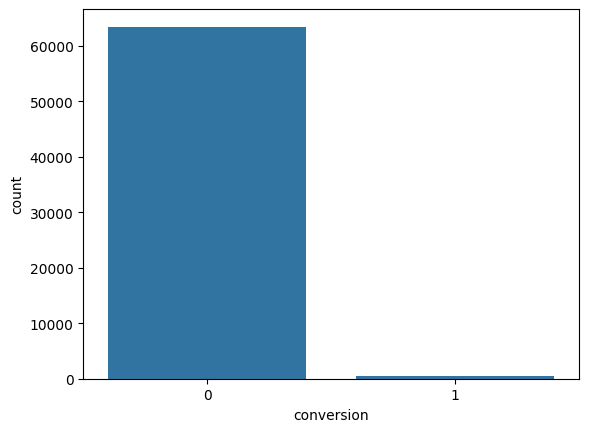

In [221]:
sns.countplot(data=dataset,x="conversion")
plt.show()

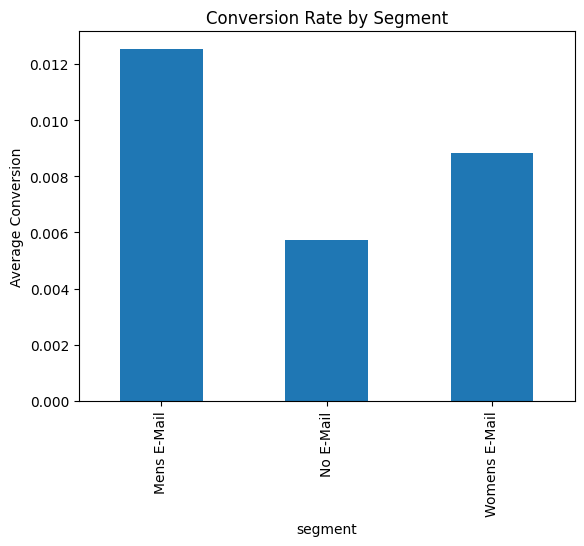

In [222]:
conversion = dataset.groupby("segment")["conversion"].mean()

conversion.plot(kind="bar")
plt.title("Conversion Rate by Segment")
plt.ylabel("Average Conversion")
plt.show()

# DAG

In [223]:
from dowhy import CausalModel

model = CausalModel(
    data=dataset,

    treatment="segment",

    outcome="conversion",

    common_causes=[
        "recency",
        "history",
        "mens",
        "womens",
        "zip_code",
        "newbie",
        "channel"
    ]
)

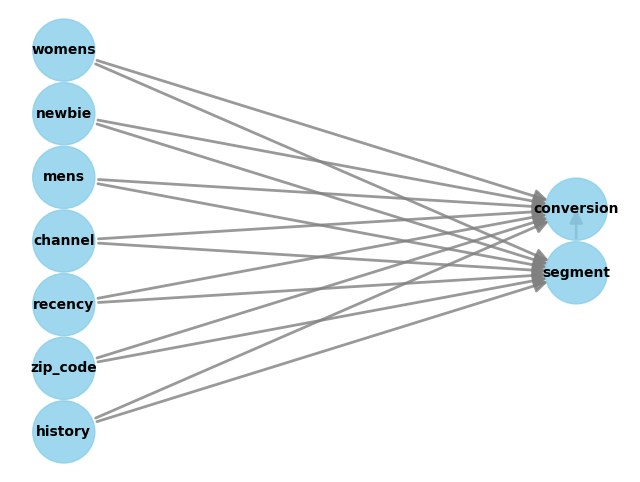

In [224]:
model.view_model()

In [225]:
identified_estimand = model.identify_effect()

print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
    d                                                                        
──────────(E[conversion|history,zip_code,recency,channel,mens,newbie,womens])
d[segment]                                                                   
Estimand assumption 1, Unconfoundedness: If U→{segment} and U→conversion then P(conversion|segment,history,zip_code,recency,channel,mens,newbie,womens,U) = P(conversion|segment,history,zip_code,recency,channel,mens,newbie,womens)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
    d                                                                        
──────────(E[conversion|history,zip_code,recency,channel,mens,newbie,womens])
d[segment]                                                       

[1 0]


<Axes: xlabel='segment', ylabel='count'>

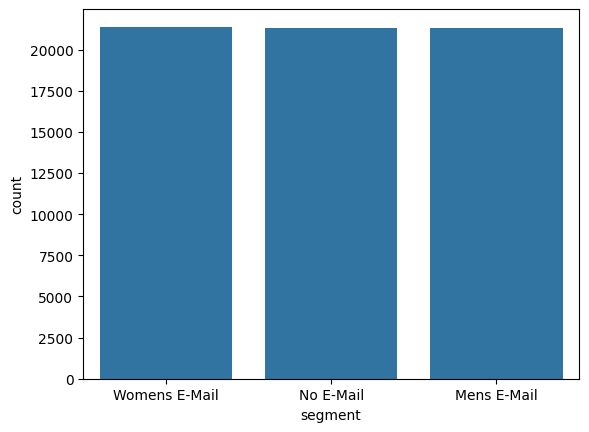

In [245]:
print(T.unique())

sns.countplot(
    data=dataset,
    x="segment"
)

<Axes: xlabel='history', ylabel='Count'>

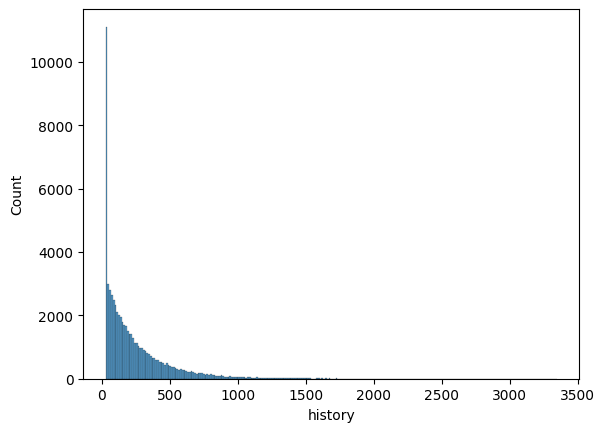

In [246]:
# hostory dist
sns.histplot(
    dataset["history"]
)

<Axes: >

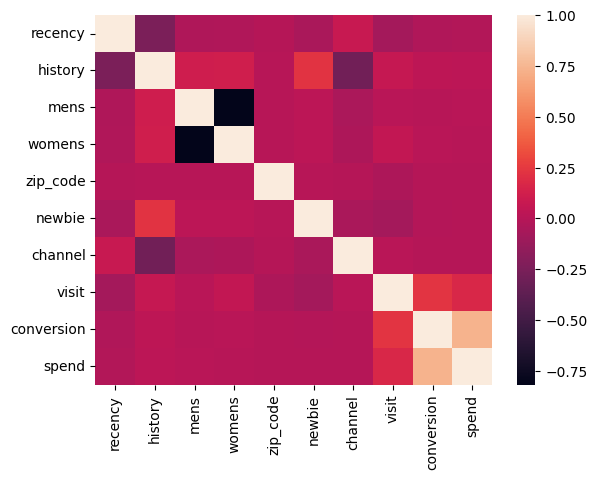

In [248]:
sns.heatmap(
    dataset.corr(numeric_only=True),
    # annot=True
)

# train test split


In [226]:
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.2,
    random_state=42
)

In [227]:
X_train

,recency,history,mens,womens,zip_code,newbie,channel
43820,4,228.99,0,1,1,0,2
36500,11,130.61,0,1,1,1,2
38039,9,29.99,0,1,0,0,2
1954,2,184.59,0,1,2,1,2
28361,9,96.46,1,0,1,0,1
...,...,...,...,...,...,...,...
62570,3,276.21,0,1,2,0,1
38158,4,43.49,0,1,2,0,1
860,8,492.53,1,1,0,1,1
15795,5,72.28,1,0,2,1,2


In [228]:
T_train

43820    1
36500    0
38039    1
1954     0
28361    1
        ..
62570    1
38158    1
860      1
15795    1
56422    0
Name: segment, Length: 51200, dtype: int64

In [229]:
Y_train

43820    0
36500    0
38039    0
1954     0
28361    0
        ..
62570    0
38158    0
860      0
15795    0
56422    0
Name: conversion, Length: 51200, dtype: int64

In [230]:
print(X_train.shape)
print(X_test.shape)
print(T_train.shape)
print(T_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(51200, 7)
(12800, 7)
(51200,)
(12800,)
(51200,)
(12800,)


In [231]:
from pathlib import Path
import joblib

output_dir = Path("backend\data\processed")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(X, output_dir / "X.pkl")
joblib.dump(T, output_dir / "T.pkl")
joblib.dump(Y, output_dir / "Y.pkl")

print("X, T, Y saved successfully.")

X, T, Y saved successfully.
